# Machine Learning Study - Learning Different Models 

## Basics 

In this notebook we will cover the fundamental machine learning models:
- Linear Regression
- Logistic Regression
- k-means
- k-nearest neighbors
- decision tree (Gini or entropy)
- 2 layer Neural Networks (NN)
    - with backpropogation

For each model we cover:
1. What is the objective of the the model and what is the learning procedure?
2. What does it assume about the data?
3. What are the main 2-3 hyperparameters?
4. How useful is it under class imbalance?
5. What does inference cost, and how would you serve and monitor it?

#### **Data Disclaimer**

For each model we will use base dataset provided by scikit-learn(sklearn) and seaborn (sns). If a custom dataset is used, it will be noted as such. Links and references will be provided.

#### **Base Imports**

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. Linear Regression**

Linear regression is a ml-model that predicts an output given an array of inputs. With an array x s.t. $x\in{\mathbb{R}^n}$ we call this method Multiple Linear Regression.

$$ \hat{y} = \beta_1x + \beta_0 \text{ where } x\in{\mathbb{R}^n}$$

For linear regression:
1. The goal of the linear regression model is to estimate some output $y$ using inputs $x$. The learning procedure depends on the loss function we define as $L(h)$. The main goal for learning is to minimize the chosen loss funciton $L(h)$. 

2. The main thing assumed about a linear regression model is that the data is all quantitative (ie. non categorical data).  

3. There are no hyperparameters for a classic linear regression model, the training and weights come from the data. 

4. Since linear regression does not deal with categorical data it is not affected by class imbalance in the sense other models might be. A situation where a linear regression does not deal with imbalance well is skewed data. Example if we have a dataset of homes where 99% are 500k but 1% are 10M, a linear regression model cannot adapt well.  

5. The inference cost for a linear regression model is almost none. It is easy to use and deploy to something like an API for predictions. However, a linear regression model fall subject to data drift. As real world data changes, a linear regression model becomes less accurate, and thus needs retraining with updated data. 



#### **Loading Data for Linear Regression**

We will load the seaborn "tips" dataset and try to predict 'tip' from 'total bill' and 'size'.

In [3]:
tips = sns.load_dataset("tips")
tips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


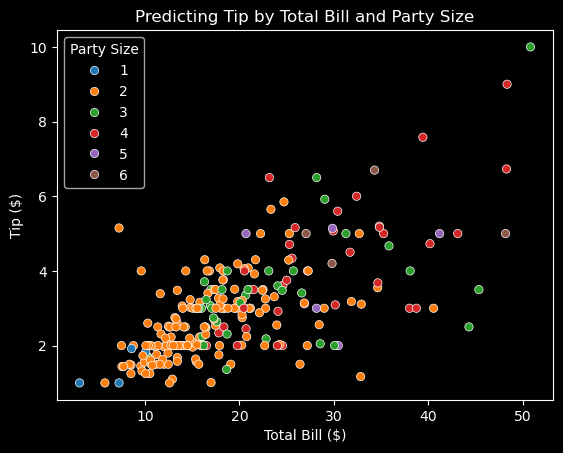

In [4]:
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='size', palette='tab10')
plt.title("Predicting Tip by Total Bill and Party Size")
plt.xlabel("Total Bill ($)")
plt.ylabel("Tip ($)")
plt.legend(title="Party Size")
plt.show()

#### **Splitting the data and modeling**

In [5]:
# Import model specific packages
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Organize data
X = np.array(tips[['total_bill','size']])
y = np.array(tips['tip'])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state = 42)

# Fit data
model = LinearRegression()
model.fit(X_train, y_train)

# print model stats
print(f'Slope (Coefficient): {model.coef_[0]:.4f}')
print(f'Intercept: {model.intercept_:.4f}')

# Make predictions
y_pred = model.predict(X_test)
print(f'R-squared Score: {r2_score(y_test, y_pred):.4f}')
print(f'Mean Squared Error: {mean_squared_error(y_test, y_pred):.4f}')


Slope (Coefficient): 0.0911
Intercept: 0.4424
R-squared Score: 0.3606
Mean Squared Error: 0.8429


#### **Evaluating the model**

R² and MSE on their own don't tell us much. We check:
1. **All coefficients**: there are 2 features, so there are 2 slopes.
2. **Baseline**: does the model beat always predicting the mean tip?
3. **Train vs test**: a big gap means overfitting.
4. **Cross-validation**: is the score stable across different splits?
5. **Residuals**: is there structure the model missed?
6. **Worst predictions**: where does it fail?

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import cross_val_score

features = ['total_bill', 'size']
# Find coefficents
print(pd.Series(model.coef_, index=features).round(4), '\n')
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)

def scores(m, X, y):
    p = m.predict(X)
    return {'RMSE': mean_squared_error(y,p) ** 0.5,
            'MAE': mean_absolute_error(y,p),
            'R2': r2_score(y,p)}

# Find difference between our model and chance
report = pd.DataFrame({
    'baseline (test)': scores(baseline, X_test, y_test),
    'model (train)': scores(model, X_train, y_train),
    'model (test)': scores(model, X_test, y_test)
})

print(report,'\n')

# Cross Validation
cv = -cross_val_score(LinearRegression(), X, y, cv=5, scoring='neg_root_mean_squared_error')
print(f'5-fold CV RSME: {cv.mean():.3f} {cv.std():.3f}')

total_bill    0.0911
size          0.3083
dtype: float64 

      baseline (test)  model (train)  model (test)
RMSE         1.186404       1.051832      0.918076
MAE          1.008305       0.762150      0.696126
R2          -0.067794       0.481959      0.360590 

5-fold CV RSME: 1.001 0.206


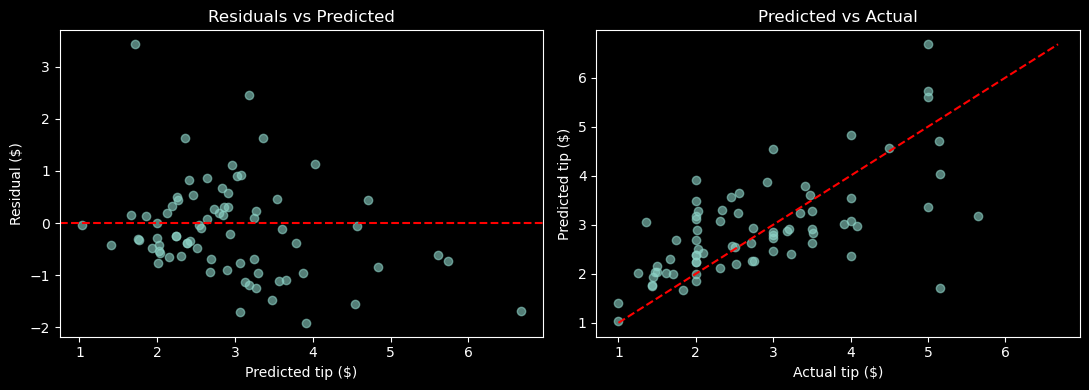

,total_bill,size,actual,predicted,abs_error
56,7.25,2.0,5.15,1.72,3.43
62,23.33,2.0,5.65,3.18,2.47
2,24.55,4.0,2.00,3.91,1.91
15,18.64,3.0,1.36,3.07,1.71
29,48.17,6.0,5.00,6.68,1.68


In [7]:
# 5. Residual diagnostics
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(y_pred, residuals, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set(title='Residuals vs Predicted', xlabel='Predicted tip ($)', ylabel='Residual ($)')

lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[1].scatter(y_test, y_pred, alpha=0.6)
axes[1].plot(lims, lims, color='red', linestyle='--')
axes[1].set(title='Predicted vs Actual', xlabel='Actual tip ($)', ylabel='Predicted tip ($)')

plt.tight_layout()
plt.show()

# 6. Worst 5 predictions
errors = pd.DataFrame(X_test, columns=features).assign(
    actual=y_test, predicted=y_pred.round(2), abs_error=np.abs(residuals).round(2))
errors.sort_values('abs_error', ascending=False).head(5)

### Personal Learning 

Termonology: 
- Mean Average Error (MAE): 

    - Take $\frac{1}{n}\sum^n_{i=1} |\hat{y}_i - y_i|$ 
    - Best when each error is consequentially the same 

- Root Mean Squared Error (RMSE): 

    - Take $\frac{1}{n}\sqrt{\sum_{i=1}^n (\hat{y}_i - y_i)^2}$
    - Best when data is affected by heavy outliers

- $R^2$ Coeff: 

    - The fraction of variation that the model explains
    - If
        - $R^2 < 0$, then model is worse than guessing
        - $R^2 \approx 0$, then model is about guessing
        - $R^2 > 0$, then model is better than guessing
        - $R^2 = 1$, model is perfect

Model Coeff:
- The models coefficents explain how much of the prediction change based on some input $x_i$
- The intercept explain the base prediciton such that $x=0$

Cross Validation (CV):
- Splits the data in $x$ parts, uses $(x-1)$ parts to train the data, then tests on the last one. 
- Takes the average of all of them according to an error function (e.g. RMSE, MAE) and gives mean $ \pm $ std

DummyRegressor:
- "Trains" against the data. Reality finds the mean and always outputs the means as an estimate. Used for validating a model.

Testing:
- Show the Results of "Luck" i.e. the DummyRegressor
- Show results of model on training data to see how the model performs on already seen data.
- Show results of model on testing data to see how the model performs on not seen data.
- The difference between the 3 tell you how well the model is performing 
    - Ideally training $\approx$ test; training $\ne$ DummyRegressor

Residuals:
- Plotting risiduals shows us if we have the right model.
    - If the risidual look like a cloud or have no appearent pattern, the shape is correct.
    - If not, maybe a different model would be better for the data

- Plotting the actual vs predicted 
    - Tells how well our prediction is to the real data


### **Room for optimization?**

For a linear regression model, we can potentially optimize the model by changign the loss function uses. Instead of MAE, RMSE, or $R^2$. We can try to use Huber loss. 

In [8]:
# Same data and split, different loss: Huber (squared error for small misses, absolute for big ones)
from sklearn.linear_model import HuberRegressor

huber = HuberRegressor().fit(X_train, y_train)

# Test-split comparison: coefficients + metrics
print(pd.DataFrame({
    'MSE loss (LinearRegression)': {**dict(zip(features, model.coef_)), **scores(model, X_test, y_test)},
    'Huber loss (HuberRegressor)': {**dict(zip(features, huber.coef_)), **scores(huber, X_test, y_test)},
}).T.round(3), '\n')

# 5-fold CV RMSE, so one lucky split can't decide the winner
for name, m in [('MSE loss', LinearRegression()), ('Huber loss', HuberRegressor())]:
    cv = -cross_val_score(m, X, y, cv=5, scoring='neg_root_mean_squared_error')
    print(f'{name:10s} 5-fold CV RMSE: {cv.mean():.3f} ± {cv.std():.3f}')

                             total_bill   size   RMSE    MAE     R2
MSE loss (LinearRegression)       0.091  0.308  0.918  0.696  0.361
Huber loss (HuberRegressor)       0.094  0.319  0.924  0.697  0.352 

MSE loss   5-fold CV RMSE: 1.001 ± 0.206
Huber loss 5-fold CV RMSE: 1.013 ± 0.206


Not much changed in terms of optimization, we could leave this to furthur investigation, but the outliers in this data set make it hard for a linear regression model to get completely accurate. 

### End of File